### Agent vs Node
- Node: graph 안에서 실행단위 하나
- Agent: LLM을 가지고 있어야함. 필요한 Tool 호출 가능. 판단하는 주체

# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움
- 멀티 에이전트는 작업을 역할별로 나누고, 각 결과를 다음 담당자에게 전달
    - 멀티 에이전트 종류
    - Network: 동료 간 상호 위임이 가능한 연결 구조
    - Supervisor: 여러 담당자의 순서를 결정하는 중앙 관리자
    - Hierarchical: 팀 안에 팀이 있는 계층적 조직
    - Custom: 위 세가지에 벗어나는 구조


### HandOff
- 현재 담당자가 다른 담당자에게 실행 제어권을 넘기는 것

In [63]:
from typing import TypedDict, Dict
from langgraph.graph import StateGraph, START, END

In [29]:
class HandoffState(TypedDict, total=False):
    request: str
    department: str
    answer: str
    
def triage(state: HandoffState):
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    return {"department": dept}

def coding(state: HandoffState):
    return {"answer": f"[코딩 담당] {state['request']} > 예제: for x in [1, 2, 3]: print(x)"}

def writing(state: HandoffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

def route_handoff(state: HandoffState):
    return state['department']


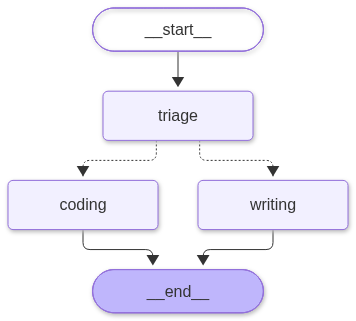

In [30]:
builder = StateGraph(HandoffState)
builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)
builder.add_edge(START, "triage")
builder.add_conditional_edges("triage", route_handoff, {"coding": "coding", "writing": "writing"})
builder.add_edge("coding", END)
builder.add_edge("writing", END)
handoff_graph = builder.compile()
handoff_graph

In [31]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request": q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩 담당] 파이썬 for문 설명해줘 > 예제: for x in [1, 2, 3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [32]:
for update in handoff_graph.stream({"request": "파이썬 리스트 예제"}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩 담당] 파이썬 리스트 예제 > 예제: for x in [1, 2, 3]: print(x)'}}


In [34]:
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from typing import TypedDict, Literal

In [35]:
llm = ChatOpenAI(model="gpt-5.6-luna", temperature=0)

# Command: 실질적으로 handoff를 실행해주는 객체
# 1. 분류 에이전트
def triage(state: HandoffState) -> Command[Literal["coding", "writing"]]:
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    # update: 공유 상태(State)에 department 값을 저장.
    # goto: 다음에 실행할 노드를 지정
    return Command(update={"department": dept}, goto=dept)

# 2. 코딩 에이전트
def coding(state: HandoffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}

# 3. 글쓰기 에이전트
def writing(state: HandoffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요. \n요청: {state['request']}"
    )
    return {"answer": response.content}

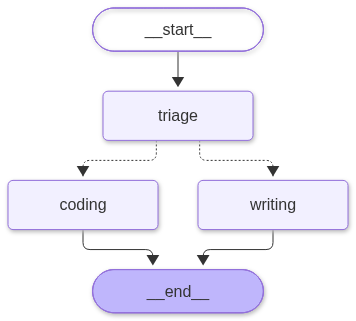

In [36]:
builder = StateGraph(HandoffState)
builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)
builder.add_edge(START, "triage")
builder.add_edge("coding", END)
builder.add_edge("writing", END)
graph = builder.compile()
graph


In [37]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request": q})
    print(f"\n질문: {q}")  
    print(f"담당: {result['department']}")
    print(f"답변: {result["answer"]}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: # 파이썬 `for`문이란?

`for`문은 **여러 개의 값을 하나씩 꺼내서 반복 실행**할 때 사용합니다.

## 기본 문법

```python
for 변수 in 반복할_자료:
    실행할_문장
```

예를 들어 리스트의 값을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "포도"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
포도
```

`fruit` 변수에 리스트의 값이 하나씩 들어갑니다.

---

## 숫자를 반복할 때: `range()`

`range()`는 숫자의 범위를 만들어 줍니다.

```python
for i in range(5):
    print(i)
```

실행 결과:

```text
0
1
2
3
4
```

`range(5)`는 **0부터 4까지**입니다.  
마지막 숫자 `5`는 포함되지 않습니다.

### 1부터 5까지 출력하기

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

### 2씩 증가하기

```python
for i in range(0, 10, 2):
    print(i)
```

결과:

```text
0
2
4
6
8
```

형식은 다음과 같습니다.

```python
range(시작값, 끝값, 증가값)
```

---

## 문자열도 반복할 수 있습니다

문자열의 글자를 하나씩 꺼낼 수 있습니다.

```python
for char in "Python":
    print(char)
```

결과:

```text
P
y
t
h
o
n
```

---

## 리스트의 합계 구하기

```python
numbers = [10, 20, 30, 40]
total = 0

for number in numbers:
    total = tot

### 1. Network
각 전문 에이전트로 되어 있으며 직접 이웃 에이전트로 handoff를 함

In [53]:
from tavily import TavilyClient
from dotenv import load_dotenv
from pathlib import Path
from pydantic import BaseModel, Field
import os, json
import matplotlib.pyplot as plt

In [62]:
load_dotenv()

True

In [42]:
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError(".env에 openai api key 설정!")
llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "get-5.6-luna"), temperature=0)

In [45]:
OUTPUT_DIR = Path("multi_agent_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [ ]:
def ask(system: str, user: str) -> str:
    """시스템 지시와 사용자 입력을 구분해서 LLM을 호출합니다."""
    response = llm.invoke([("system", system), ("human", user)])
    return str(response.content)

In [ ]:
class ChartState(TypedDict, total=False):
    question: str
    sources: list[dict]
    data: list[dict]
    summary: str
    chart_path: str
    error: str
    
class ChartData(TypedDict):
    label: str
    value: float

In [47]:
def search_web(query: str) -> list[dict]:
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError("TAVILY KEY ERROR!")
    result = TavilyClient(api_key=key).search(query=query, max_results=5)
    return [{"title": x.get("title", ""), "url": x.get("url", ""), "content": x.get("content", "")[:1500]} for x in result.get("results", [])]

In [51]:
class ResearchData(BaseModel):
    data: list[ChartData] = Field(description="출처에서 확인된 수치만")
    summary: str

In [52]:
research_llm = llm.with_structured_output(ResearchData)

In [54]:
def researcher(state: ChartState) -> Command[Literal["chart", "__end__"]]:
    sources = search_web(state['question'])
    parsed = research_llm.invoke([
        ("system", "검색 결과에 명시된 값만 추출하세요. 추정하거나 없는 수치를 생성하지 마세요. 각 수치의 단위가 일관되어야 합니다. 확인 불가능하면 data를 빈 목록으로 반환하세요."),
        ("human", json.dumps({"question":state["question"], "sources":sources}, ensure_ascii=False))
    ])
    if not parsed.data:
        return Command(updata={"sources": sources, "error": "검증 가능한 수치가 없습니다,"}, goto=END)
    return Command(update={"sources": sources, "data": [x.model_dump() if hasattr(x, "model_dump") else x for x in parsed.data], "summary": parsed.summary}, goto="chart")

In [55]:
def chart(state: ChartState) -> Command[Literal["__end__"]]:
    rows = state["data"]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar([r["label"] for r in rows], [r["value"] for r in rows])
    ax.set_title("Research results (verify units and sources)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    path = OUTPUT_DIR / "research_chart.png"
    fig.savefig(path, dpi=140)
    plt.show()
    plt.close(fig)
    return Command(update={"chart_path":str(path)}, goto=END)

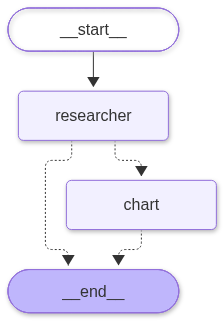

In [56]:
builder = StateGraph(ChartState)
builder.add_node("researcher", researcher)
builder.add_node("chart", chart)
builder.add_edge(START, "researcher")
network_chart = builder.compile()
network_chart

/var/folders/cr/h0m56hfx095g2g1b7pwy0hgh0000gn/T/ipykernel_7811/4192484299.py:7: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/cr/h0m56hfx095g2g1b7pwy0hgh0000gn/T/ipykernel_7811/4192484299.py:9: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=140)
/Users/songjeong-geun/Desktop/데스크탑 - 송정근의 MacBook Air/데스크탑 /KDT/14_AGENT/.venv.nosync/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


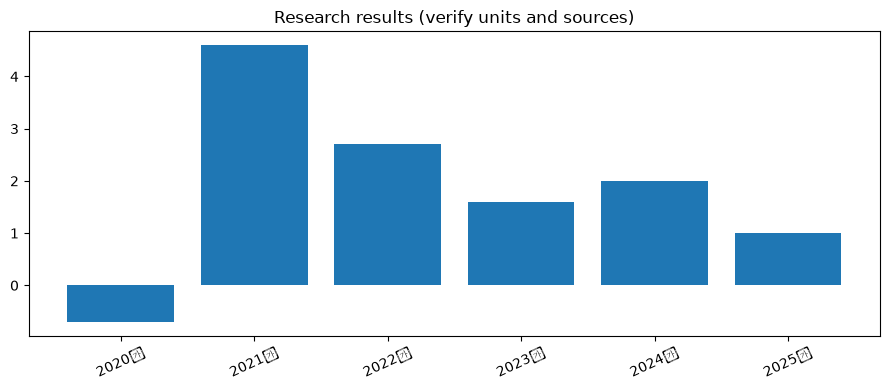

In [58]:
result = network_chart.invoke({"question": "2020년부터 2025년까지 한국의 연도별 실질 GDP 성장률(%)"}, config={"recursion_limit": 5})

### 멀티 에이전트 기반(네트워크) AI 맞춤형 학습 진단 및 문제 출제 시스템
학생의 과목별 학습 점수를 분석하여 가장 취약한 학습 영역을 찾아내고, 해당 영역에 대한 맞춤형 문제를 자동으로 출제하는 AI 학습 진단 멀티 에이전트 시스템을 개발

- Diagnosis Agent: 학생의 영역별 점수를 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성
- Quiz Agent: 진단 결과를 전달받아 취약 영역에 대한 객관식 문제를 생성

```
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}

1. 학생의 학습 점수를 입력받음
2. 모든 점수가 0~100점 사이인지 검사
3. 가장 점수가 낮은 학습 영역을 찾음
4. LLM을 이용하여 학생의 학습 상태를 3문장으로 진단
5. 진단 결과를 문제 출제 에이전트에게 전달
6. LLM을 이용하여 취약 영역에 대한 객관식 문제 3개를 생성
7. 각 문제에 정답과 해설을 포함
8. 최종 진단 결과와 생성된 문제를 출력
```

In [98]:
# 1. 에이전트 간 공유할 상태(State) 정의
class LearningState(TypedDict, total=False):
    scores: dict[str, int]
    weakest_subject: str
    diagnosis: str
    quiz: str

In [99]:
def triage_subject(scores: Dict[str, int]) -> str:
    """점수를 분석하여 가장 취약한 과목의 이름을 반환"""
    for subject, score in scores.items():
        if not (0 <= score <= 100):
            raise ValueError("점수 범위 확인!")
            
    return min(scores, key=scores.get)

In [100]:
# 1. 학생의 영역별 점수를 분석하고 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성하는 agent
def diagnosis(state: LearningState) -> Command[Literal["quiz", "__end__"]]:
    scores = state.get("scores", {})
    
    # 순수 함수를 호출하여 취약 과목 추출
    weakest = triage_subject(scores)
    
    system_prompt = "당신은 학생의 성취도를 정밀하게 분석하고 개선 방향을 제시하는 수석 교육 진단 전문가입니다."
    user_prompt = f"학생 점수: {scores}\n이 데이터를 바탕으로 가장 취약한 '{weakest}' 과목에 대한 현재 학습 상태와 보완점을 정확히 3문장으로 진단해 주세요."
    
    result_text = ask(system_prompt, user_prompt)
    
    # weakest_subject와 diagnosis 결과를 함께 상태에 업데이트
    return Command(
        update={
            "weakest_subject": weakest,
            "diagnosis": result_text.strip()
        },
        goto="quiz"
    )
    
# 2. 진단 결과를 전달받아 취약 영역에 대한 객관식 문제를 생성
def quiz(state: LearningState) -> Command[Literal["__end__"]]:
    weakest = state["weakest_subject"]
    diagnosis = state["diagnosis"]
    
    system_prompt = "당신은 취약점 보완을 위한 맞춤형 평가 문제를 출제하는 교육 전문가입니다. 항상 문제, 보기 4개, 정답, 상세한 해설을 포함하여 출제합니다."
    user_prompt = f"다음 진단 결과를 참고하여 작성하세요: {diagnosis}\n\n위 진단을 바탕으로 취약한 '{weakest}' 과목의 개념을 다지는 객관식 문제 3개를 출제해 주세요."
    
    result_text = ask(system_prompt, user_prompt)
    
    return Command(
        update={"quiz": result_text.strip()},
        goto=END
    )

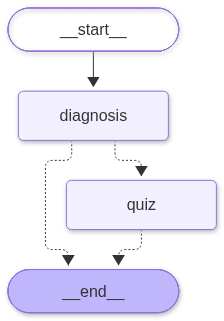

In [101]:
builder = StateGraph(LearningState)
builder.add_node("diagnosis", diagnosis)
builder.add_node("quiz", quiz)
builder.add_edge(START, "diagnosis")
learning_network = builder.compile()
learning_network

In [102]:
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}

result = learning_network.invoke({"scores": scores})
print(result)

{'scores': {'파이썬 기초문법': 90, '데이터 분석': 75, '딥러닝': 60}, 'weakest_subject': '딥러닝', 'diagnosis': '딥러닝 점수는 60점으로 파이썬 기초문법(90점)과 데이터 분석(75점)에 비해 가장 낮아, 핵심 개념과 적용 능력이 충분히 정착되지 않은 상태입니다.  \n특히 신경망 구조, 손실 함수·최적화, 과적합 방지와 같은 기초 이론을 이해하고 이를 코드로 구현하는 연습이 부족할 가능성이 높습니다.  \n기초 수학·머신러닝 개념을 복습한 뒤 간단한 모델을 직접 구현하고, 학습·검증 결과를 분석하는 프로젝트를 단계적으로 수행하는 보완이 필요합니다.', 'quiz': '## 문제 1. 신경망의 기본 구조와 순전파\n\n다음은 입력 \\(x\\)를 하나의 뉴런에 통과시키는 과정이다.\n\n\\[\nz = w^Tx+b,\\qquad a = \\mathrm{ReLU}(z)\n\\]\n\n여기서 \\(x=[2, -1]\\), \\(w=[0.5, 1]\\), \\(b=-0.5\\)일 때 뉴런의 출력 \\(a\\)는 얼마인가?\n\n① \\(-0.5\\)  \n② \\(0\\)  \n③ \\(0.5\\)  \n④ \\(1.5\\)\n\n### 정답\n② \\(0\\)\n\n### 해설\n먼저 가중합 \\(z\\)를 계산한다.\n\n\\[\nz = (0.5 \\times 2) + (1 \\times -1) - 0.5\n\\]\n\n\\[\nz = 1 - 1 - 0.5 = -0.5\n\\]\n\nReLU 함수는 다음과 같이 정의된다.\n\n\\[\n\\mathrm{ReLU}(z)=\\max(0,z)\n\\]\n\n따라서\n\n\\[\na=\\mathrm{ReLU}(-0.5)=0\n\\]\n\n이다.\n\n- ① \\(-0.5\\): 활성화 함수 적용 전의 값이다.\n- ③ \\(0.5\\), ④ \\(1.5\\): 가중치, 입력값 또는 편향을 잘못 계산한 결과다.\n\nReLU는 음수 입력을 0으로 바꾸고 양수 입력은 

In [103]:
# 강사님 코드
class StudyState(TypedDict, total=False):
    scores: dict[str, int]
    weakness: str
    diagnosis: str
    quiz: str
    
def diagnosis_node(state: StudyState) -> Command[Literal["quiz"]]:
    scores = state["scores"]
    if not scores or any(not 0 <= v <= 100 for v in scores.values()):
        raise ValueError("영역별 점수를 0 ~ 100 사이로 입력하세요.")
    weak = min(scores, key=scores.get)
    explanation = ask("당신은 친절한 학습 진단 전문가입니다. 점수의 의미를 과장하지 말고 3문장으로 분석하세요.", f"영역별 점수: {scores}, 최저 영역: {weak}")
    return Command(update={"weakness": weak, "diagnosis": explanation}, goto="quiz")

def quiz_node(state: StudyState) -> Command[Literal["__end__"]]:
    content = ask("당신은 학습 문제 출제 전문가입니다. 지정된 취약 영역에 대해 객관식 3문제를 만들고 각 문항에 정답과 쉬운 해설을 붙이세요. 애매한 문항은 피하세요.", f"취약 영역: {state['weakness']}\n 진단: {state['diagnosis']}")
    return Command(update={"quiz": content}, goto=END)

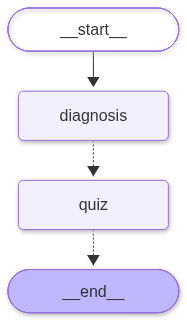

In [104]:
builder = StateGraph(StudyState)
builder.add_node("diagnosis", diagnosis_node)
builder.add_node("quiz", quiz_node)
builder.add_edge(START, "diagnosis")
study_network = builder.compile()
study_network

In [105]:
result = study_network.invoke({"scores": {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}}, config={"recursion_limit": 5})

In [106]:
print("[진단]", result["diagnosis"], "\n[문제]", result["quiz"])

[진단] 파이썬 기초문법은 90점으로 매우 탄탄하며, 데이터 분석은 75점으로 기본기가 형성된 편입니다.  
딥러닝은 60점으로 다른 영역보다 낮아 핵심 개념과 모델 학습 과정에 대한 보완이 필요합니다.  
딥러닝의 기초 이론, 데이터 전처리, 간단한 모델 구현을 중심으로 학습하고, 작은 실습 프로젝트로 이해도를 점검해 보세요. 
[문제] ## 딥러닝 기초 객관식 문제 3문항

### 1번. 딥러닝의 기본 개념

다음 중 **ReLU 활성화 함수**에 대한 설명으로 옳은 것은 무엇인가요?

① 입력값이 모두 0과 1 사이로 변환된다.  
② 입력값이 음수이면 0, 양수이면 입력값 그대로 출력한다.  
③ 입력값의 합을 확률로 변환한다.  
④ 항상 입력값의 제곱을 출력한다.  

**정답: ②**

**해설:**  
ReLU 함수는 다음과 같이 동작합니다.

```python
ReLU(x) = max(0, x)
```

따라서 음수 입력은 0이 되고, 양수 입력은 그대로 출력됩니다. ReLU는 신경망에서 비선형성을 추가하기 위해 자주 사용됩니다.

---

### 2번. 데이터 전처리

머신러닝이나 딥러닝 모델에 입력하기 전에 이미지의 픽셀 값이 `0~255` 범위에 있다면, 다음 중 가장 적절한 전처리는 무엇인가요?

① 모든 픽셀 값을 문자열로 변환한다.  
② 픽셀 값을 `0~1` 범위로 정규화한다.  
③ 픽셀 값을 무작위로 섞어 모두 다른 값으로 만든다.  
④ 픽셀 값을 모두 255로 바꾼다.  

**정답: ②**

**해설:**  
이미지 픽셀 값을 다음처럼 나누면 `0~1` 범위로 변환할 수 있습니다.

```python
x = x / 255.0
```

값의 범위를 작게 조정하면 모델이 데이터를 더 안정적으로 학습하는 데 도움이 됩니다.

---

### 3번. 간단한 모델 구현

다음 코드는 이진 분류 모델의 마지막 출력층을 정의한 것입니다.

```python
model.add(Dense(1, activation='sigmoid'))
``